# Karşılaştırmalı Duygu Analizi Projesi

## 3.2 BERT Tabanlı Duygu Analizi

Bu çalışmada İngilizce ve Türkçe metinler üzerinde
BERT tabanlı duygu analizi gerçekleştirilecektir.

### 1. İngilizce Model
- Model: cardiffnlp/twitter-roberta-base-sentiment-latest
- Yöntem: Hazır eğitilmiş model ile tahmin

### 2. Türkçe Model
- Model: dbmdz/bert-base-turkish-cased
- Yöntem: Fine-tuning
- Epoch: 2-3
- Learning Rate: 2e-5
- Batch Size: 16
- Max Length: 128

### 3. Değerlendirme
- Pozitif
- Negatif
- Nötr

### 4. Çıktılar
- preds_bert_en.csv
- preds_bert_tr.csv

In [ ]:
import torch

print("CUDA kullanılabilir mi:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA kullanılabilir mi: True
GPU: Tesla T4


In [ ]:
!pip install -q transformers datasets accelerate scikit-learn pandas matplotlib

In [ ]:
import torch
import transformers
import pandas as pd
import sklearn

print("GPU:", torch.cuda.get_device_name(0))
print("Transformers:", transformers.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

print("Kurulum başarılı!")

GPU: Tesla T4
Transformers: 5.22.1
Pandas: 2.2.3
Scikit-learn: 1.6.1
Kurulum başarılı!


In [ ]:
from transformers import pipeline

EN_MODEL_NAME = "cardiffnlp/twitter-roberta-base-sentiment-latest"

english_model = pipeline(
    "sentiment-analysis",
    model=EN_MODEL_NAME,
    device=0
)

print("İngilizce RoBERTa modeli başarıyla yüklendi!")

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

İngilizce RoBERTa modeli başarıyla yüklendi!


In [ ]:
sample_texts = [
    "I absolutely love this product!",
    "This is the worst experience ever.",
    "The product arrived yesterday."
]

predictions = english_model(sample_texts)

for text, prediction in zip(sample_texts, predictions):
    print("Metin:", text)
    print("Tahmin:", prediction)
    print("-" * 50)

Metin: I absolutely love this product!
Tahmin: {'label': 'positive', 'score': 0.9843719601631165}
--------------------------------------------------
Metin: This is the worst experience ever.
Tahmin: {'label': 'negative', 'score': 0.9453436732292175}
--------------------------------------------------
Metin: The product arrived yesterday.
Tahmin: {'label': 'positive', 'score': 0.5657423138618469}
--------------------------------------------------


In [1]:
import torch

print("GPU:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

GPU: False


In [5]:
from google.colab import files

uploaded = files.upload()

Saving test_en.csv to test_en.csv
Saving test_tr.csv to test_tr.csv
Saving train_tr.csv to train_tr.csv


In [6]:
import pandas as pd
import os

print("Yüklenen dosyalar:", os.listdir())

for file in ["test_en.csv", "test_tr.csv", "train_tr.csv"]:
    df = pd.read_csv(file)
    print(f"\n--- {file} ---")
    print("Satır sayısı:", len(df))
    print("Sütunlar:", df.columns.tolist())
    print("\nSınıf dağılımı:")
    print(df["label"].value_counts())

Yüklenen dosyalar: ['.config', 'test_tr.csv', 'train_tr.csv', 'test_en.csv', 'sample_data']

--- test_en.csv ---
Satır sayısı: 3000
Sütunlar: ['id', 'text', 'label']

Sınıf dağılımı:
label
Nötr       1000
Negatif    1000
Pozitif    1000
Name: count, dtype: int64

--- test_tr.csv ---
Satır sayısı: 3000
Sütunlar: ['id', 'text', 'label']

Sınıf dağılımı:
label
Nötr       1000
Negatif    1000
Pozitif    1000
Name: count, dtype: int64

--- train_tr.csv ---
Satır sayısı: 30000
Sütunlar: ['id', 'text', 'label']

Sınıf dağılımı:
label
Negatif    10000
Pozitif    10000
Nötr       10000
Name: count, dtype: int64


In [7]:
!pip install -q transformers torch

In [8]:
from transformers import pipeline

EN_MODEL_NAME = "cardiffnlp/twitter-roberta-base-sentiment-latest"

english_model = pipeline(
    "sentiment-analysis",
    model=EN_MODEL_NAME,
    device=-1
)

print("İngilizce RoBERTa modeli başarıyla yüklendi!")

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

İngilizce RoBERTa modeli başarıyla yüklendi!


In [10]:
print("İşlem kontrolü")
print("Veri sayısı:", len(test_en))
print("Model hazır mı:", english_model is not None)

İşlem kontrolü
Veri sayısı: 3000
Model hazır mı: True


In [12]:
from tqdm.auto import tqdm

texts = test_en["text"].astype(str).tolist()
all_results = []

for i in tqdm(range(0, len(texts), 32)):
    batch = texts[i:i+32]

    batch_results = english_model(
        batch,
        batch_size=32,
        truncation=True,
        max_length=128
    )

    all_results.extend(batch_results)

label_map = {
    "positive": "Pozitif",
    "negative": "Negatif",
    "neutral": "Nötr"
}

test_en["pred"] = [
    label_map[r["label"].lower()] for r in all_results
]

preds_en = test_en[["id", "text", "label", "pred"]].copy()
preds_en.columns = ["id", "text", "true", "pred"]

import os
os.makedirs("results", exist_ok=True)
preds_en.to_csv("results/preds_bert_en.csv", index=False)

print("Tamamlandı:", len(preds_en))

  0%|          | 0/94 [00:00<?, ?it/s]

Tamamlandı: 3000


In [13]:
print("Tahmin dağılımı:")
print(preds_en["pred"].value_counts())

print("\nGerçek sınıf dağılımı:")
print(preds_en["true"].value_counts())

print("\nİlk 10 tahmin:")
display(preds_en.head(10))

print("\nDosya kontrolü:")
import os
print(os.path.exists("results/preds_bert_en.csv"))

Tahmin dağılımı:
pred
Negatif    1111
Pozitif    1083
Nötr        806
Name: count, dtype: int64

Gerçek sınıf dağılımı:
true
Nötr       1000
Negatif    1000
Pozitif    1000
Name: count, dtype: int64

İlk 10 tahmin:


,id,text,true,pred
0,en_0,@SouthwestAir's CEO Kelly draws record crowd t...,Nötr,Pozitif
1,en_1,@SouthwestAir How do I retroactively add previ...,Nötr,Nötr
2,en_2,@JetBlue woof I'm on the red cArpet http://t.c...,Nötr,Nötr
3,en_3,@USAirways That's 1h 10m waiting to get my bag...,Negatif,Negatif
4,en_4,@united thank you! My second flight I already ...,Pozitif,Pozitif
5,en_5,"@united Alright, thank you. Is there a page th...",Nötr,Nötr
6,en_6,@SouthwestAir any chance they will change this...,Nötr,Nötr
7,en_7,@JetBlue Airways Corporation (NASDAQ:JBLU) Rea...,Pozitif,Nötr
8,en_8,@AmericanAir I didn't want to Cancelled Flight...,Negatif,Negatif
9,en_9,Thank you for sending more details @AmericanA...,Pozitif,Pozitif



Dosya kontrolü:
True


In [14]:
from google.colab import files

files.download("results/preds_bert_en.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import torch

print("GPU kullanılabilir mi?", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU belleği:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

GPU kullanılabilir mi? True
GPU: Tesla T4
GPU belleği: 14.56 GB


In [2]:
!pip install -q transformers datasets accelerate scikit-learn

In [4]:
from google.colab import files

uploaded = files.upload()

Saving test_tr.csv to test_tr.csv
Saving train_tr.csv to train_tr.csv


In [5]:
import pandas as pd
import torch

train_tr = pd.read_csv("train_tr.csv")
test_tr = pd.read_csv("test_tr.csv")

print("GPU:", torch.cuda.get_device_name(0))
print("Eğitim verisi:", len(train_tr))
print("Test verisi:", len(test_tr))
print(train_tr["label"].value_counts())

GPU: Tesla T4
Eğitim verisi: 30000
Test verisi: 3000
label
Negatif    10000
Pozitif    10000
Nötr       10000
Name: count, dtype: int64


In [6]:
import pandas as pd
import numpy as np
import torch
import time

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)
from datasets import Dataset

# Sabit değerler
SEED = 42
MODEL_NAME = "dbmdz/bert-base-turkish-cased"

label2id = {
    "Negatif": 0,
    "Nötr": 1,
    "Pozitif": 2
}

id2label = {v: k for k, v in label2id.items()}

# Eğitim verisini hazırla
train_tr["label_id"] = train_tr["label"].map(label2id)

train_df, val_df = train_test_split(
    train_tr,
    test_size=0.10,
    random_state=SEED,
    stratify=train_tr["label_id"]
)

print("Eğitim:", len(train_df))
print("Doğrulama:", len(val_df))

# Tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

train_dataset = Dataset.from_pandas(
    train_df[["text", "label_id"]].rename(
        columns={"label_id": "labels"}
    ),
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_df[["text", "label_id"]].rename(
        columns={"label_id": "labels"}
    ),
    preserve_index=False
)

train_dataset = train_dataset.map(tokenize, batched=True)
val_dataset = val_dataset.map(tokenize, batched=True)

train_dataset = train_dataset.remove_columns(["text"])
val_dataset = val_dataset.remove_columns(["text"])

print("Tokenization tamamlandı!")

# Model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

print("BERTurk modeli hazır!")
print("GPU:", torch.cuda.get_device_name(0))

Eğitim: 27000
Doğrulama: 3000


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/251k [00:00<?, ?B/s]

Map:   0%|          | 0/27000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dbmdz/bert-base-turkish-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERTurk modeli hazır!
GPU: Tesla T4


In [7]:
import os
import time
from transformers import TrainingArguments, Trainer

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = logits.argmax(axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro"
        )
    }

training_args = TrainingArguments(
    output_dir="./models/berturk",
    num_train_epochs=2,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=100,
    fp16=True,
    seed=42,
    report_to="none",
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

start_time = time.time()

train_result = trainer.train()

training_time = time.time() - start_time

print("\nEĞİTİM TAMAMLANDI!")
print("Eğitim süresi (dakika):", round(training_time / 60, 2))
print("Eğitim metrikleri:", train_result.metrics)

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.163188,0.160304,0.940667,0.940604
2,0.111412,0.195912,0.947000,0.946962


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


EĞİTİM TAMAMLANDI!
Eğitim süresi (dakika): 7.8
Eğitim metrikleri: {'train_runtime': 466.6838, 'train_samples_per_second': 115.71, 'train_steps_per_second': 7.234, 'total_flos': 3552031139328000.0, 'train_loss': 0.15982499789287694, 'epoch': 2.0}


In [8]:
# Türkçe test verisini hazırla
test_tr["label_id"] = test_tr["label"].map(label2id)

test_dataset = Dataset.from_pandas(
    test_tr[["text", "label_id"]].rename(
        columns={"label_id": "labels"}
    ),
    preserve_index=False
)

test_dataset = test_dataset.map(tokenize, batched=True)
test_dataset = test_dataset.remove_columns(["text"])

# En iyi modelle tahmin
test_output = trainer.predict(test_dataset)

predictions = np.argmax(test_output.predictions, axis=-1)

# Tahminleri etiketlere dönüştür
test_tr["pred"] = [id2label[int(x)] for x in predictions]

# Sonuç dosyası
preds_tr = test_tr[["id", "text", "label", "pred"]].copy()
preds_tr.columns = ["id", "text", "true", "pred"]

import os
os.makedirs("results", exist_ok=True)

preds_tr.to_csv(
    "results/preds_bert_tr.csv",
    index=False
)

print("Türkçe tahminler tamamlandı:", len(preds_tr))
print("\nTahmin dağılımı:")
print(preds_tr["pred"].value_counts())

print("\nDosya kaydedildi:",
      os.path.exists("results/preds_bert_tr.csv"))

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Türkçe tahminler tamamlandı: 3000

Tahmin dağılımı:
pred
Pozitif    1060
Nötr       1003
Negatif     937
Name: count, dtype: int64

Dosya kaydedildi: True


In [9]:
model_dir = "models/berturk"

trainer.save_model(model_dir)
tokenizer.save_pretrained(model_dir)

print("BERTurk modeli kaydedildi:", model_dir)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERTurk modeli kaydedildi: models/berturk


In [10]:
from google.colab import files

files.download("results/preds_bert_tr.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import json

training_info = {
    "model": "dbmdz/bert-base-turkish-cased",
    "epochs": 2,
    "learning_rate": 2e-5,
    "batch_size": 16,
    "max_length": 128,
    "seed": 42,
    "train_samples": 27000,
    "validation_samples": 3000,
    "test_samples": 3000,
    "training_time_minutes": round(training_time / 60, 2),
    "gpu": torch.cuda.get_device_name(0)
}

with open("results/berturk_training_info.json", "w", encoding="utf-8") as f:
    json.dump(training_info, f, ensure_ascii=False, indent=4)

files.download("results/berturk_training_info.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
import os

print("Mevcut klasör:", os.getcwd())
print("Dosyalar:", os.listdir())
print("Models klasörü var mı:", os.path.exists("models"))

Mevcut klasör: /content
Dosyalar: ['.config', 'sample_data']
Models klasörü var mı: False


In [3]:
from google.colab import files
uploaded = files.upload()

Saving test_tr.csv to test_tr.csv
Saving train_tr.csv to train_tr.csv


In [4]:
import pandas as pd
import torch

train_tr = pd.read_csv("train_tr.csv")
test_tr = pd.read_csv("test_tr.csv")

print("GPU:", torch.cuda.get_device_name(0))
print("Eğitim:", len(train_tr))
print("Test:", len(test_tr))

GPU: Tesla T4
Eğitim: 30000
Test: 3000


In [5]:
!pip install -q transformers datasets accelerate scikit-learn

In [6]:
import os
import time
import torch
import pandas as pd
import numpy as np

from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

# Sabit ayarlar
SEED = 42
MODEL_NAME = "dbmdz/bert-base-turkish-cased"

label2id = {
    "Negatif": 0,
    "Nötr": 1,
    "Pozitif": 2
}

id2label = {v: k for k, v in label2id.items()}

# Eğitim / doğrulama ayrımı
train_tr["label_id"] = train_tr["label"].map(label2id)

train_df, val_df = train_test_split(
    train_tr,
    test_size=0.10,
    random_state=SEED,
    stratify=train_tr["label_id"]
)

# Tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

train_dataset = Dataset.from_pandas(
    train_df[["text", "label_id"]].rename(
        columns={"label_id": "labels"}
    ),
    preserve_index=False
).map(tokenize, batched=True)

val_dataset = Dataset.from_pandas(
    val_df[["text", "label_id"]].rename(
        columns={"label_id": "labels"}
    ),
    preserve_index=False
).map(tokenize, batched=True)

train_dataset = train_dataset.remove_columns(["text"])
val_dataset = val_dataset.remove_columns(["text"])

# Model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

print("Hazırlık tamamlandı!")
print("GPU:", torch.cuda.get_device_name(0))
print("Eğitim:", len(train_dataset))
print("Doğrulama:", len(val_dataset))

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/251k [00:00<?, ?B/s]

Map:   0%|          | 0/27000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  445MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dbmdz/bert-base-turkish-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Hazırlık tamamlandı!
GPU: Tesla T4
Eğitim: 27000
Doğrulama: 3000


In [7]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels, predictions, average="macro"
        )
    }

training_args = TrainingArguments(
    output_dir="/content/berturk_checkpoints",
    num_train_epochs=2,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=3,
    logging_steps=100,
    fp16=True,
    seed=42,
    report_to="none",
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

start_time = time.time()
train_result = trainer.train()
training_time = time.time() - start_time

print("EĞİTİM TAMAMLANDI!")
print("Süre (dakika):", round(training_time / 60, 2))
print(train_result.metrics)

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.159652,0.152328,0.946667,0.946568
2,0.100190,0.181189,0.950000,0.949926


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

EĞİTİM TAMAMLANDI!
Süre (dakika): 7.82
{'train_runtime': 468.5959, 'train_samples_per_second': 115.238, 'train_steps_per_second': 7.205, 'total_flos': 3552031139328000.0, 'train_loss': 0.16241101800547958, 'epoch': 2.0}


In [8]:
import os

FINAL_DIR = "/content/berturk_final"

trainer.save_model(FINAL_DIR)
tokenizer.save_pretrained(FINAL_DIR)

print("Model dosyaları:")
print(os.listdir(FINAL_DIR))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model dosyaları:
['model.safetensors', 'tokenizer_config.json', 'config.json', 'training_args.bin', 'tokenizer.json']


In [9]:
import shutil

zip_path = shutil.make_archive(
    "/content/berturk_model_backup",
    "zip",
    root_dir="/content",
    base_dir="berturk_final"
)

print("ZIP hazır:", zip_path)
print("Boyut (MB):", round(os.path.getsize(zip_path) / 1024**2, 2))

ZIP hazır: /content/berturk_model_backup.zip
Boyut (MB): 391.82


In [10]:
from google.colab import files

files.download("/content/berturk_model_backup.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import pandas as pd

test_df = pd.read_csv("/content/test_tr.csv")

print("Test satır sayısı:", len(test_df))
print(test_df.head())
print(test_df["label"].value_counts())

Test satır sayısı: 3000
     id                                               text    label
0  tr_0                Alman kıyı savunması da ateş açtı .     Nötr
1  tr_1               Faaliyetler gençler düzeyinde oldu .     Nötr
2  tr_2  O zamanki yönetimlerin özel sektöre getirdiği ...     Nötr
3  tr_3  saldiriya ugradik berbat bir oteldi odalarda m...  Negatif
4  tr_4       ekonomik hızlı ve orijinal daha ne olsun :))  Pozitif
label
Nötr       1000
Negatif    1000
Pozitif    1000
Name: count, dtype: int64


In [13]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_path = "/content/berturk_final"

tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path)

print("Model ve tokenizer yüklendi!")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model ve tokenizer yüklendi!


In [14]:
import numpy as np
import torch
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

# Etiket eşleştirmesi
id2label = {0: "Negatif", 1: "Nötr", 2: "Pozitif"}

# Test metinlerini tokenize et
test_encodings = tokenizer(
    test_df["text"].astype(str).tolist(),
    truncation=True,
    padding=True,
    max_length=128,
    return_tensors="pt"
)

# Modeli değerlendirmeye al
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

# Tahminleri üret
all_predictions = []

with torch.no_grad():
    for start in range(0, len(test_df), 32):
        batch = {
            key: value[start:start+32].to(device)
            for key, value in test_encodings.items()
        }

        outputs = model(**batch)
        predictions = torch.argmax(outputs.logits, dim=1)
        all_predictions.extend(predictions.cpu().numpy())

# Sonuçları CSV'ye kaydet
results_df = pd.DataFrame({
    "id": test_df["id"],
    "text": test_df["text"],
    "true_label": test_df["label"],
    "predicted_label": [id2label[p] for p in all_predictions]
})

results_df.to_csv("/content/preds_bert_tr.csv", index=False, encoding="utf-8-sig")

print("Tahmin tamamlandı!")
print(results_df["predicted_label"].value_counts())
print(results_df.head())

Tahmin tamamlandı!
predicted_label
Pozitif    1065
Nötr       1007
Negatif     928
Name: count, dtype: int64
     id                                               text true_label  \
0  tr_0                Alman kıyı savunması da ateş açtı .       Nötr   
1  tr_1               Faaliyetler gençler düzeyinde oldu .       Nötr   
2  tr_2  O zamanki yönetimlerin özel sektöre getirdiği ...       Nötr   
3  tr_3  saldiriya ugradik berbat bir oteldi odalarda m...    Negatif   
4  tr_4       ekonomik hızlı ve orijinal daha ne olsun :))    Pozitif   

  predicted_label  
0            Nötr  
1            Nötr  
2            Nötr  
3         Negatif  
4         Pozitif  


Accuracy: 0.9457 (94.57%)
Macro-F1: 0.9455 (94.55%)

Sınıf bazında sonuçlar:
              precision    recall  f1-score   support

     Pozitif       0.90      0.95      0.92      1000
     Negatif       0.95      0.88      0.92      1000
        Nötr       0.99      1.00      1.00      1000

    accuracy                           0.95      3000
   macro avg       0.95      0.95      0.95      3000
weighted avg       0.95      0.95      0.95      3000



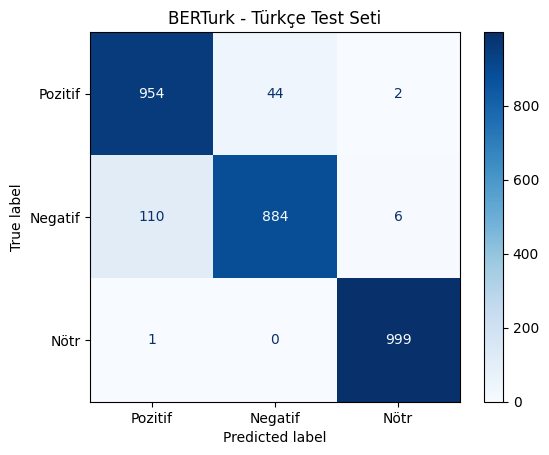

Güncel tahmin dosyası kaydedildi.


In [15]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_true = results_df["true_label"]
y_pred = results_df["predicted_label"]

accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")

print(f"Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Macro-F1: {macro_f1:.4f} ({macro_f1*100:.2f}%)")

print("\nSınıf bazında sonuçlar:")
print(classification_report(
    y_true,
    y_pred,
    labels=["Pozitif", "Negatif", "Nötr"],
    zero_division=0
))

# Confusion matrix
labels = ["Pozitif", "Negatif", "Nötr"]
cm = confusion_matrix(y_true, y_pred, labels=labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)
disp.plot(cmap="Blues", values_format="d")
plt.title("BERTurk - Türkçe Test Seti")
plt.savefig("/content/cm_bert_tr.png", dpi=300, bbox_inches="tight")
plt.show()

# Güncel sonuçları kaydet
results_df.to_csv(
    "/content/preds_bert_tr.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Güncel tahmin dosyası kaydedildi.")

In [16]:
from google.colab import files

files.download("/content/preds_bert_tr.csv")
files.download("/content/cm_bert_tr.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>